In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
dataset = "pv-italy"

In [3]:
tensor = np.load(f"../dvc-stages-outputs/{dataset}/preprocessed.npz")['data']
Y = tensor[..., 0].flatten()  # Assuming the target variable is the first feature

In [4]:
print(Y.shape)

(276488,)


In [5]:
def describeY(Y):
    print(f"Mean: {np.mean(Y)}")
    print(f"Std: {np.std(Y)}")
    print(f"Min: {np.min(Y)}")
    print(f"Max: {np.max(Y)}")
    print(f"25th percentile: {np.percentile(Y, 25)}")
    print(f"50th percentile: {np.percentile(Y, 50)}")
    print(f"75th percentile: {np.percentile(Y, 75)}")
    print(f"90th percentile: {np.percentile(Y, 90)}")
    print(f"95th percentile: {np.percentile(Y, 95)}")
    print(f"99th percentile: {np.percentile(Y, 99)}")

In [6]:
describeY(Y)

Mean: 165.24156188964844
Std: 209.9521942138672
Min: 0.0
Max: 1000.0
25th percentile: 0.0
50th percentile: 46.0
75th percentile: 314.0
90th percentile: 517.0
95th percentile: 585.0
99th percentile: 699.0


In [7]:
def plot_Y_hist(Y: np.ndarray):
    plt.hist(
        Y.flatten(), bins=1000,
    )
    plt.xlabel('Value')
    plt.ylabel('Frequency')
    plt.title('Histogram of the Data')
    # add a vertical line for each percentile
    plt.axvline(np.percentile(Y, 25), color='r', linestyle='dashed', linewidth=1, label='25th percentile')
    plt.axvline(np.percentile(Y, 50), color='g', linestyle='dashed', linewidth=1, label='50th percentile')
    plt.axvline(np.percentile(Y, 75), color='b', linestyle='dashed', linewidth=1, label='75th percentile')
    plt.axvline(np.percentile(Y, 90), color='c', linestyle='dashed', linewidth=1, label='90th percentile')
    plt.axvline(np.percentile(Y, 95), color='m', linestyle='dashed', linewidth=1, label='95th percentile')
    plt.axvline(np.percentile(Y, 99), color='y', linestyle='dashed', linewidth=1, label='99th percentile')
    plt.legend()
    plt.show()

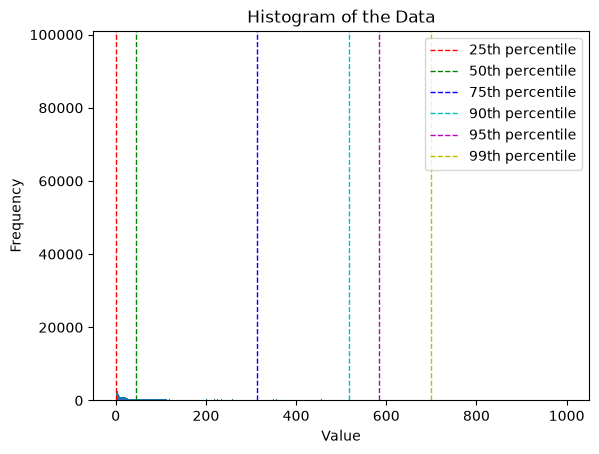

In [8]:
plot_Y_hist(Y)

In [9]:
test_indexes = np.load(f"../dvc-stages-outputs/split/val-indexes.npy")
train_indexes = np.load(f"../dvc-stages-outputs/split/train-indexes.npy")
testY = Y[test_indexes]
trainY = Y[train_indexes]

Mean: 103.02823638916016
Std: 170.06863403320312
Min: 0.0
Max: 559.0
25th percentile: 0.0
50th percentile: 0.0
75th percentile: 134.0
90th percentile: 438.80000000000007
95th percentile: 490.79999999999995
99th percentile: 528.8


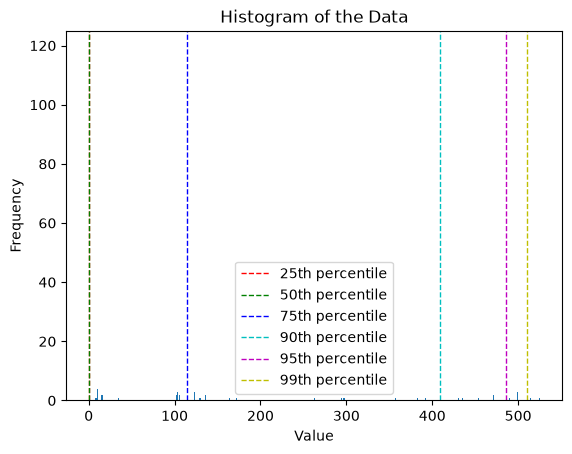

Mean MAE: 196.56004333496094
Std MAE: 10.015279769897461


In [10]:
# make predictions with a random predictor where the predictions are sampled from a distribution
# that for each float value in the train set, it samples it with probability proportional to its frequency in the train set. 
# This is equivalent to sampling from the empirical distribution of the train set.
from scipy import stats

unique_trainY, counts = np.unique(trainY, return_counts=True)
probabilities = counts / len(trainY)

describeY(trainY)

maes = []
for i in range(100000):
    predY = np.random.choice(unique_trainY, size=testY.shape, p=probabilities)
    mae = np.mean(np.abs(predY - testY))
    maes.append(mae)
    print(f"Iteration {i+1}: MAE = {mae}", end="\r")

plot_Y_hist(predY)
print(f"Mean MAE: {np.mean(maes)}")
print(f"Std MAE: {np.std(maes)}")

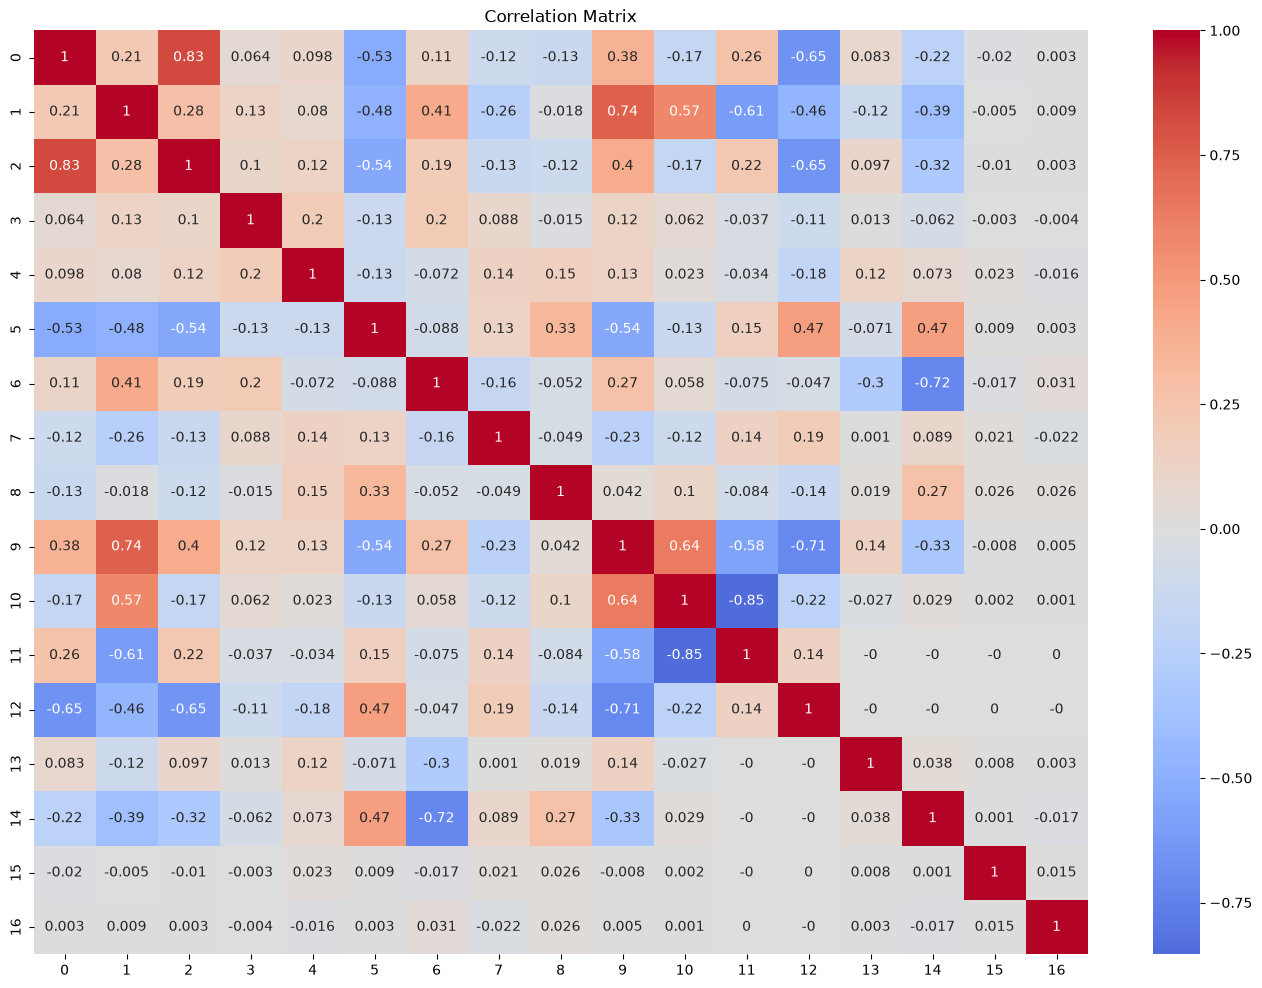

In [11]:
import seaborn as sns

corr_matrix = np.corrcoef(tensor.reshape(-1, tensor.shape[-1]), rowvar=False)
# round the correlation matrix to 2 decimal places
corr_matrix = corr_matrix.round(3)

plt.figure(figsize=(17, 12))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

In [18]:
# load the adjacency matrix and plot it with plotly as a heatmap
adj = np.load(f"../dvc-stages-outputs/{dataset}/corr-{dataset}.npy")

import plotly.graph_objects as go

fig = go.Figure(data=go.Heatmap(z=adj, colorscale='Viridis'))
fig.update_layout(title='Adjacency Matrix Heatmap', xaxis_title='Node Index', yaxis_title='Node Index')
fig.show()